C:\Users\frdch\AppData\Local\Temp\ipykernel_15336\212669011.py:43: FutureWarning: `square` is deprecated since version 0.25 and will be removed in version 0.27. Use `skimage.morphology.footprint_rectangle` instead.
  im_close = morphology.binary_closing(im_dilate, morphology.square(size))


124


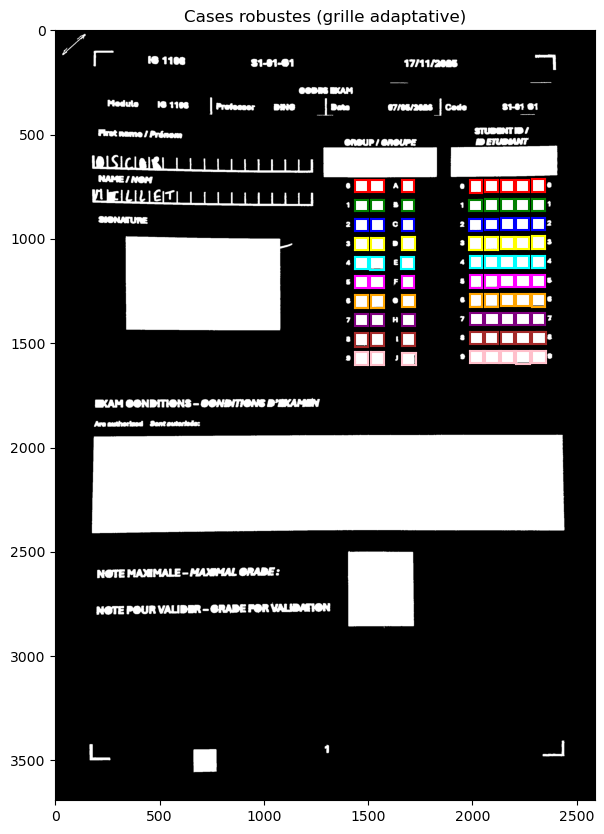

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import time
import scipy.optimize as sp
import skimage.io as ski 
import os
from skimage import color
from skimage import filters
from skimage import feature
from skimage.transform import hough_line, hough_line_peaks, rotate
from skimage import feature, morphology
from scipy.ndimage import binary_fill_holes
import skimage
from scipy import ndimage
# import skimage.io as ski
# im = ski.imread("FORM1/EXAM_FORM1_62445.jpg") # traitement contratste
# im = ski.imread("FORM1\EXAM_FORM1_61856.jpg")
im = ski.imread("FORM1\EXAM_FORM1_62401.jpg") # image de reférence
# im = ski.imread("FORM1\EXAM_FORM1_54331.jpg") # 2 image 
# im = ski.imread("FORM1\EXAM_FORM1_54331.jpg")# illisible
# im = ski.imread("FORM1\EXAM_FORM1_63807.jpeg")# illisible
# im = ski.imread("FORM1\EXAM_FORM1_58220.jpg")



# im = ski.imread("FORM1\EXAM_FORM1_50305.jpg")

if im.shape[1]>im.shape[0]:
    im = rotate(im, -90)
im_rgb = im[:, :, :3]  # on garde uniquement R, G, B
im2 = color.rgb2gray(im_rgb)

# dir(skimage.filters)
im3 = filters.sobel(im2)


size = 2
seuil = filters.threshold_otsu(im3)
im4 = im3>seuil*0.7
im35=im4.copy()
im4 = morphology.remove_small_objects(im4, min_size=100)
im_dilate = ndimage.binary_dilation(im4, structure=np.ones((size, size)))
im_close = morphology.binary_closing(im_dilate, morphology.square(size))
im4 = binary_fill_holes(im_close)
imlabel, nbCC   = skimage.measure.label(im4, connectivity=2, return_num= True)
regionprops= skimage.measure.regionprops(imlabel)

# --- 1. Filtrage initial (densité + forme) ---

dimMax = []

for k in range(len(regionprops)):

    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    pattern = imlabel[min_row:max_row, min_col:max_col] > 0
    
    dimL, diml = pattern.shape
    size = dimL * diml
    nbones = np.sum(pattern)
    density = nbones / size
    
    ratio = dimL / diml

    if density > 0.65 and 0.7 < ratio < 1.40:
        dimMax.append([k, size])
print(len(dimMax))
# --- 2. Filtre taille (relatif) ---
case = np.array(dimMax)
median_size = np.median(case[:, 1])
# print(len(dimMax))
dimMax = [x for x in dimMax if abs(x[1] - median_size) < 0.15 * median_size]

# --- 3. Centres ---
centers = []
for k, size in dimMax:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    cx = (min_col + max_col) / 2
    cy = (min_row + max_row) / 2
    centers.append((k, cx, cy, size))

centers_xy = np.array([(cx, cy) for (_, cx, cy, _) in centers])


# --- 4. Distance typique ---
D = np.sqrt(
    (centers_xy[:, None, 0] - centers_xy[None, :, 0])**2 +
    (centers_xy[:, None, 1] - centers_xy[None, :, 1])**2
)

distances = D[D > 0]
d_typical = np.median(distances)

# --- 5. Filtrage par cohérence de grille ---
filtered = []

for i in range(len(centers)):
    k, cx, cy, size = centers[i]
    
    dists = D[i]
    
    neighbors = np.sum(
        (dists > 0.7 * d_typical) &
        (dists < 1.3 * d_typical)
    )
    
    if neighbors >= 3:
        filtered.append((k, size))

# --- 6. Affichage ---
colordict= {
    0: 'red',
    1: 'green',
    2: 'blue',
    3: 'yellow',
    4: 'cyan',
    5: 'magenta',
    6: 'orange',
    7: 'purple',
    8: 'brown',
    9: 'pink'
}
colors = "gray"
plt.figure(figsize=(10, 10))
plt.imshow(im4, cmap='gray')
i=0
for k, size in filtered:
    
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    indexColor = i // 8

    # if  i%8 == 2:
    plt.plot([min_col, max_col], [min_row, min_row], f'{colordict.get(indexColor, "black")}')
    plt.plot([min_col, max_col], [max_row, max_row], f'{colordict.get(indexColor, "black")}')
    plt.plot([min_col, min_col], [min_row, max_row], f'{colordict.get(indexColor, "black")}')
    plt.plot([max_col, max_col], [min_row, max_row], f'{colordict.get(indexColor, "black")}')
    i += 1

plt.title("Cases robustes (grille adaptative)")
plt.show()




In [120]:
print(im3.shape)

(3024, 4032)


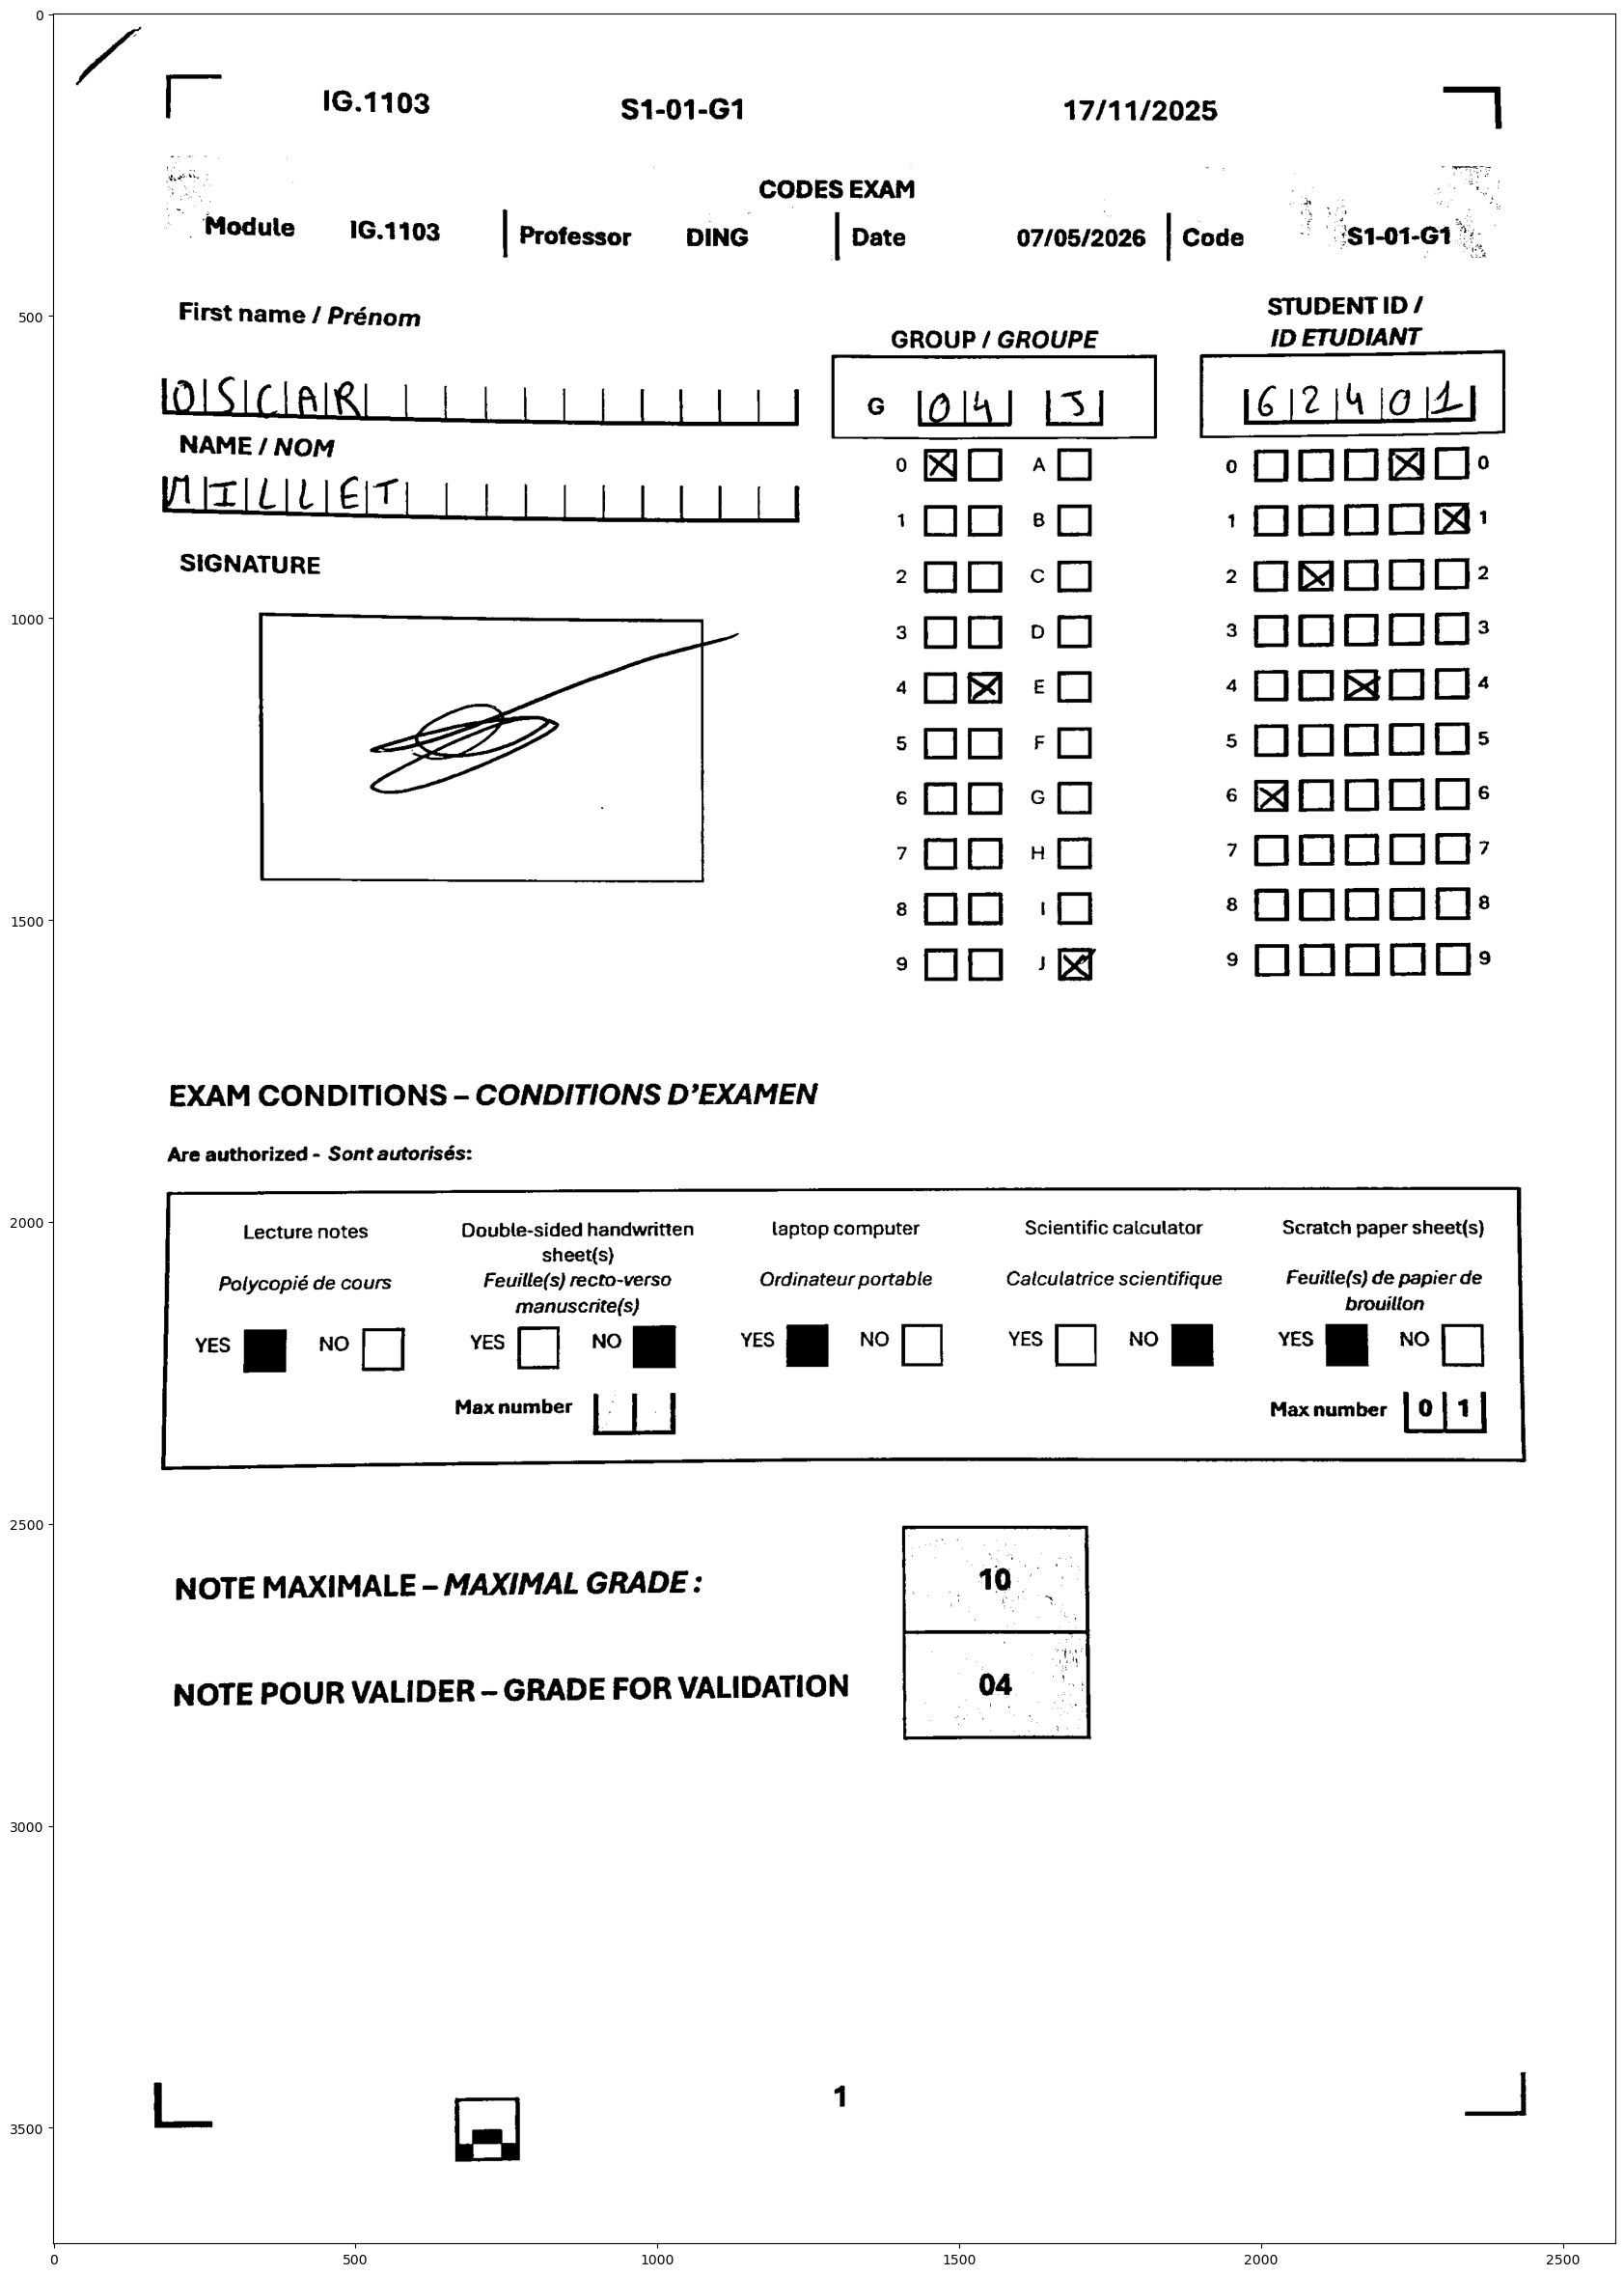

In [3]:

# seuillage Otsu
threshold = filters.threshold_otsu(im2)

# binarisation + découpage
result = (im2 > threshold)

# result = (im2 > threshold)[713:2283, 776:2350]
# 717 1510 779 1576
plt.figure(figsize=(30, 30))
plt.imshow(result, cmap='gray')

In [4]:

# construire liste avec coordonnées
boxes = []

for k, size in filtered:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    
    cx = (min_col + max_col) / 2
    cy = (min_row + max_row) / 2

    boxes.append((k, size, cx, cy, min_row, min_col, max_row, max_col))

# tri par ligne puis colonne
boxes = sorted(boxes, key=lambda x: (x[3], x[2]))  # (cy, cx)
# --- regrouper les lignes ---
rows = []
tolerance = 20  # ajuste si besoin

for b in boxes:
    placed = False
    for row in rows:
        # comparer avec le premier élément de la ligne
        if abs(b[3] - row[0][3]) < tolerance:
            row.append(b)
            placed = True
            break
    
    if not placed:
        rows.append([b])

# trier chaque ligne par colonne
for row in rows:
    row.sort(key=lambda x: x[2])  # tri par cx

# trier les lignes entre elles
# rows.sort(key=lambda r: r[0][3])
rows.sort(key=lambda r: np.mean([b[3] for b in r]))


In [100]:
# print(rows)

Case 0-0 : Score = 771.78
CASE BARREE
Case 0-1 : Score = 552.47
case vide
Case 0-2 : Score = 554.17
case vide
Case 0-3 : Score = 546.44
case vide
Case 0-4 : Score = 555.50
case vide
Case 0-5 : Score = 546.38
case vide
Case 0-6 : Score = 792.60
CASE BARREE
Case 0-7 : Score = 547.16
case vide
Case 1-0 : Score = 532.65
case vide
Case 1-1 : Score = 544.43
case vide
Case 1-2 : Score = 547.99
case vide
Case 1-3 : Score = 540.54
case vide
Case 1-4 : Score = 544.39
case vide
Case 1-5 : Score = 538.68
case vide
Case 1-6 : Score = 547.90
case vide
Case 1-7 : Score = 734.00
CASE BARREE
Case 2-0 : Score = 535.18
case vide
Case 2-1 : Score = 543.83
case vide
Case 2-2 : Score = 545.83
case vide
Case 2-3 : Score = 537.54
case vide
Case 2-4 : Score = 732.96
CASE BARREE
Case 2-5 : Score = 536.63
case vide
Case 2-6 : Score = 544.49
case vide
Case 2-7 : Score = 537.04
case vide
Case 3-0 : Score = 538.25
case vide
Case 3-1 : Score = 557.13
case vide
Case 3-2 : Score = 556.32
case vide
Case 3-3 : Score = 5

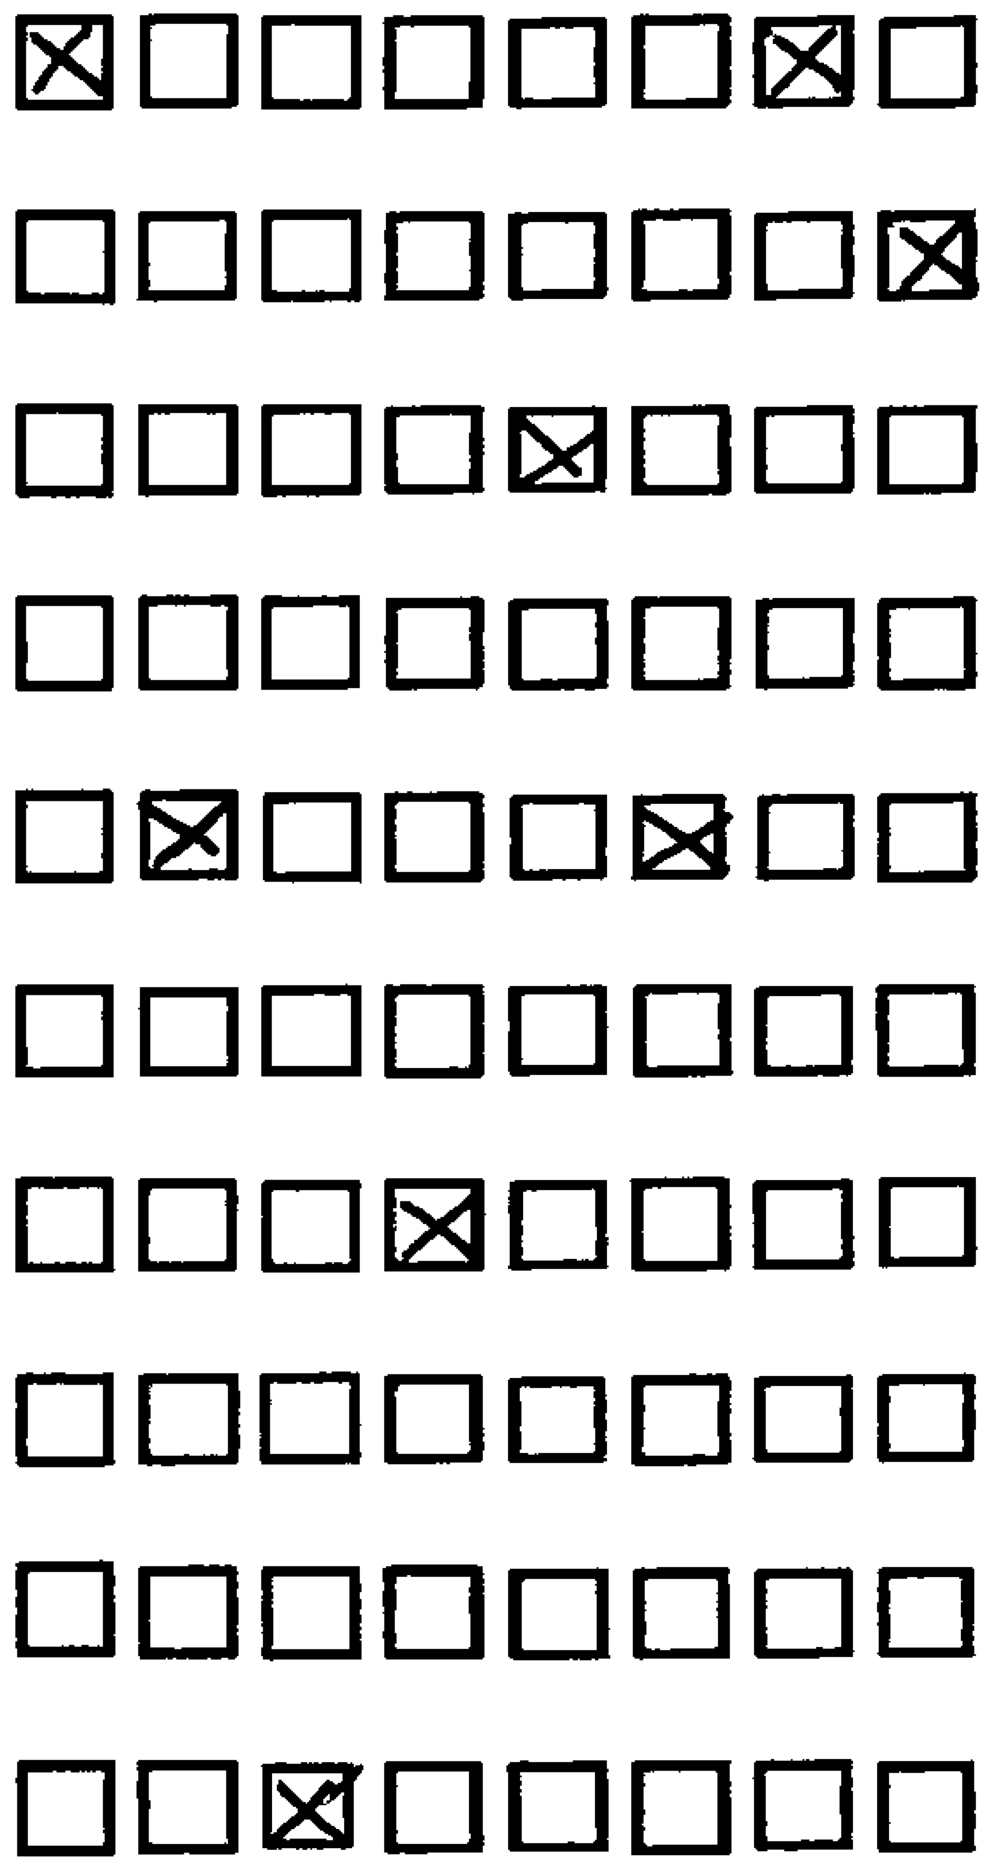

In [ ]:
fig, axes = plt.subplots(len(rows), len(rows[0]), figsize=(10, 20))
nbbare= 0 
matrice = np.zeros((len(rows), len(rows[0])))
for i, row in enumerate(rows):
    for j, b in enumerate(row):
        
        k, size, cx, cy, min_row, min_col, max_row, max_col = b
        
        case = result[min_row:max_row, min_col:max_col]
        
        
        edges = filters.sobel(case)

        score = np.sum(edges)

        print(f"Case {i}-{j} : Score = {score:.2f}")

        # seuil
        if score > 700:
            print("CASE BARREE")
            nbbare += 1
            matrice[i, j] = 1
        else:
            print("case vide")

        
        axes[i, j].imshow(case, cmap='gray')
        axes[i, j].axis('off')

print(f"Nombre de cases barrees : {nbbare}")

plt.tight_layout()
plt.show()

In [ ]:

# ===============================
# 3. LECTURE RESULTAT
# ===============================
# print(matrice)
# inversion lignes (0 en haut)
# matrice = matrice[::-1]
# print(matrice)
# 3 colonnes groupe + reste ID
mat_groupe = matrice[:, :3]
mat_id = matrice[:, 3:]

alphabet = "ABCDEFGHIJ"
# print(mat_groupe)

# --- groupe ---
groupe = ""
for j in range(mat_groupe.shape[1]):
    col = mat_groupe[:, j]
    idx = np.argmax(col)

    if j < 2:
        groupe += str(idx)
    else:
        groupe += alphabet[idx]
# print(mat_id)
# --- ID ---
identifiant = ""
for j in range(mat_id.shape[1]):
    col = mat_id[:, j]
    idx = np.argmax(col)
    identifiant += str(idx)
# print(mat_id)
print(" GROUPE =", groupe)
print(" ID =", identifiant)
abosment@aubay.com

 GROUPE = 04J
 ID = 62401


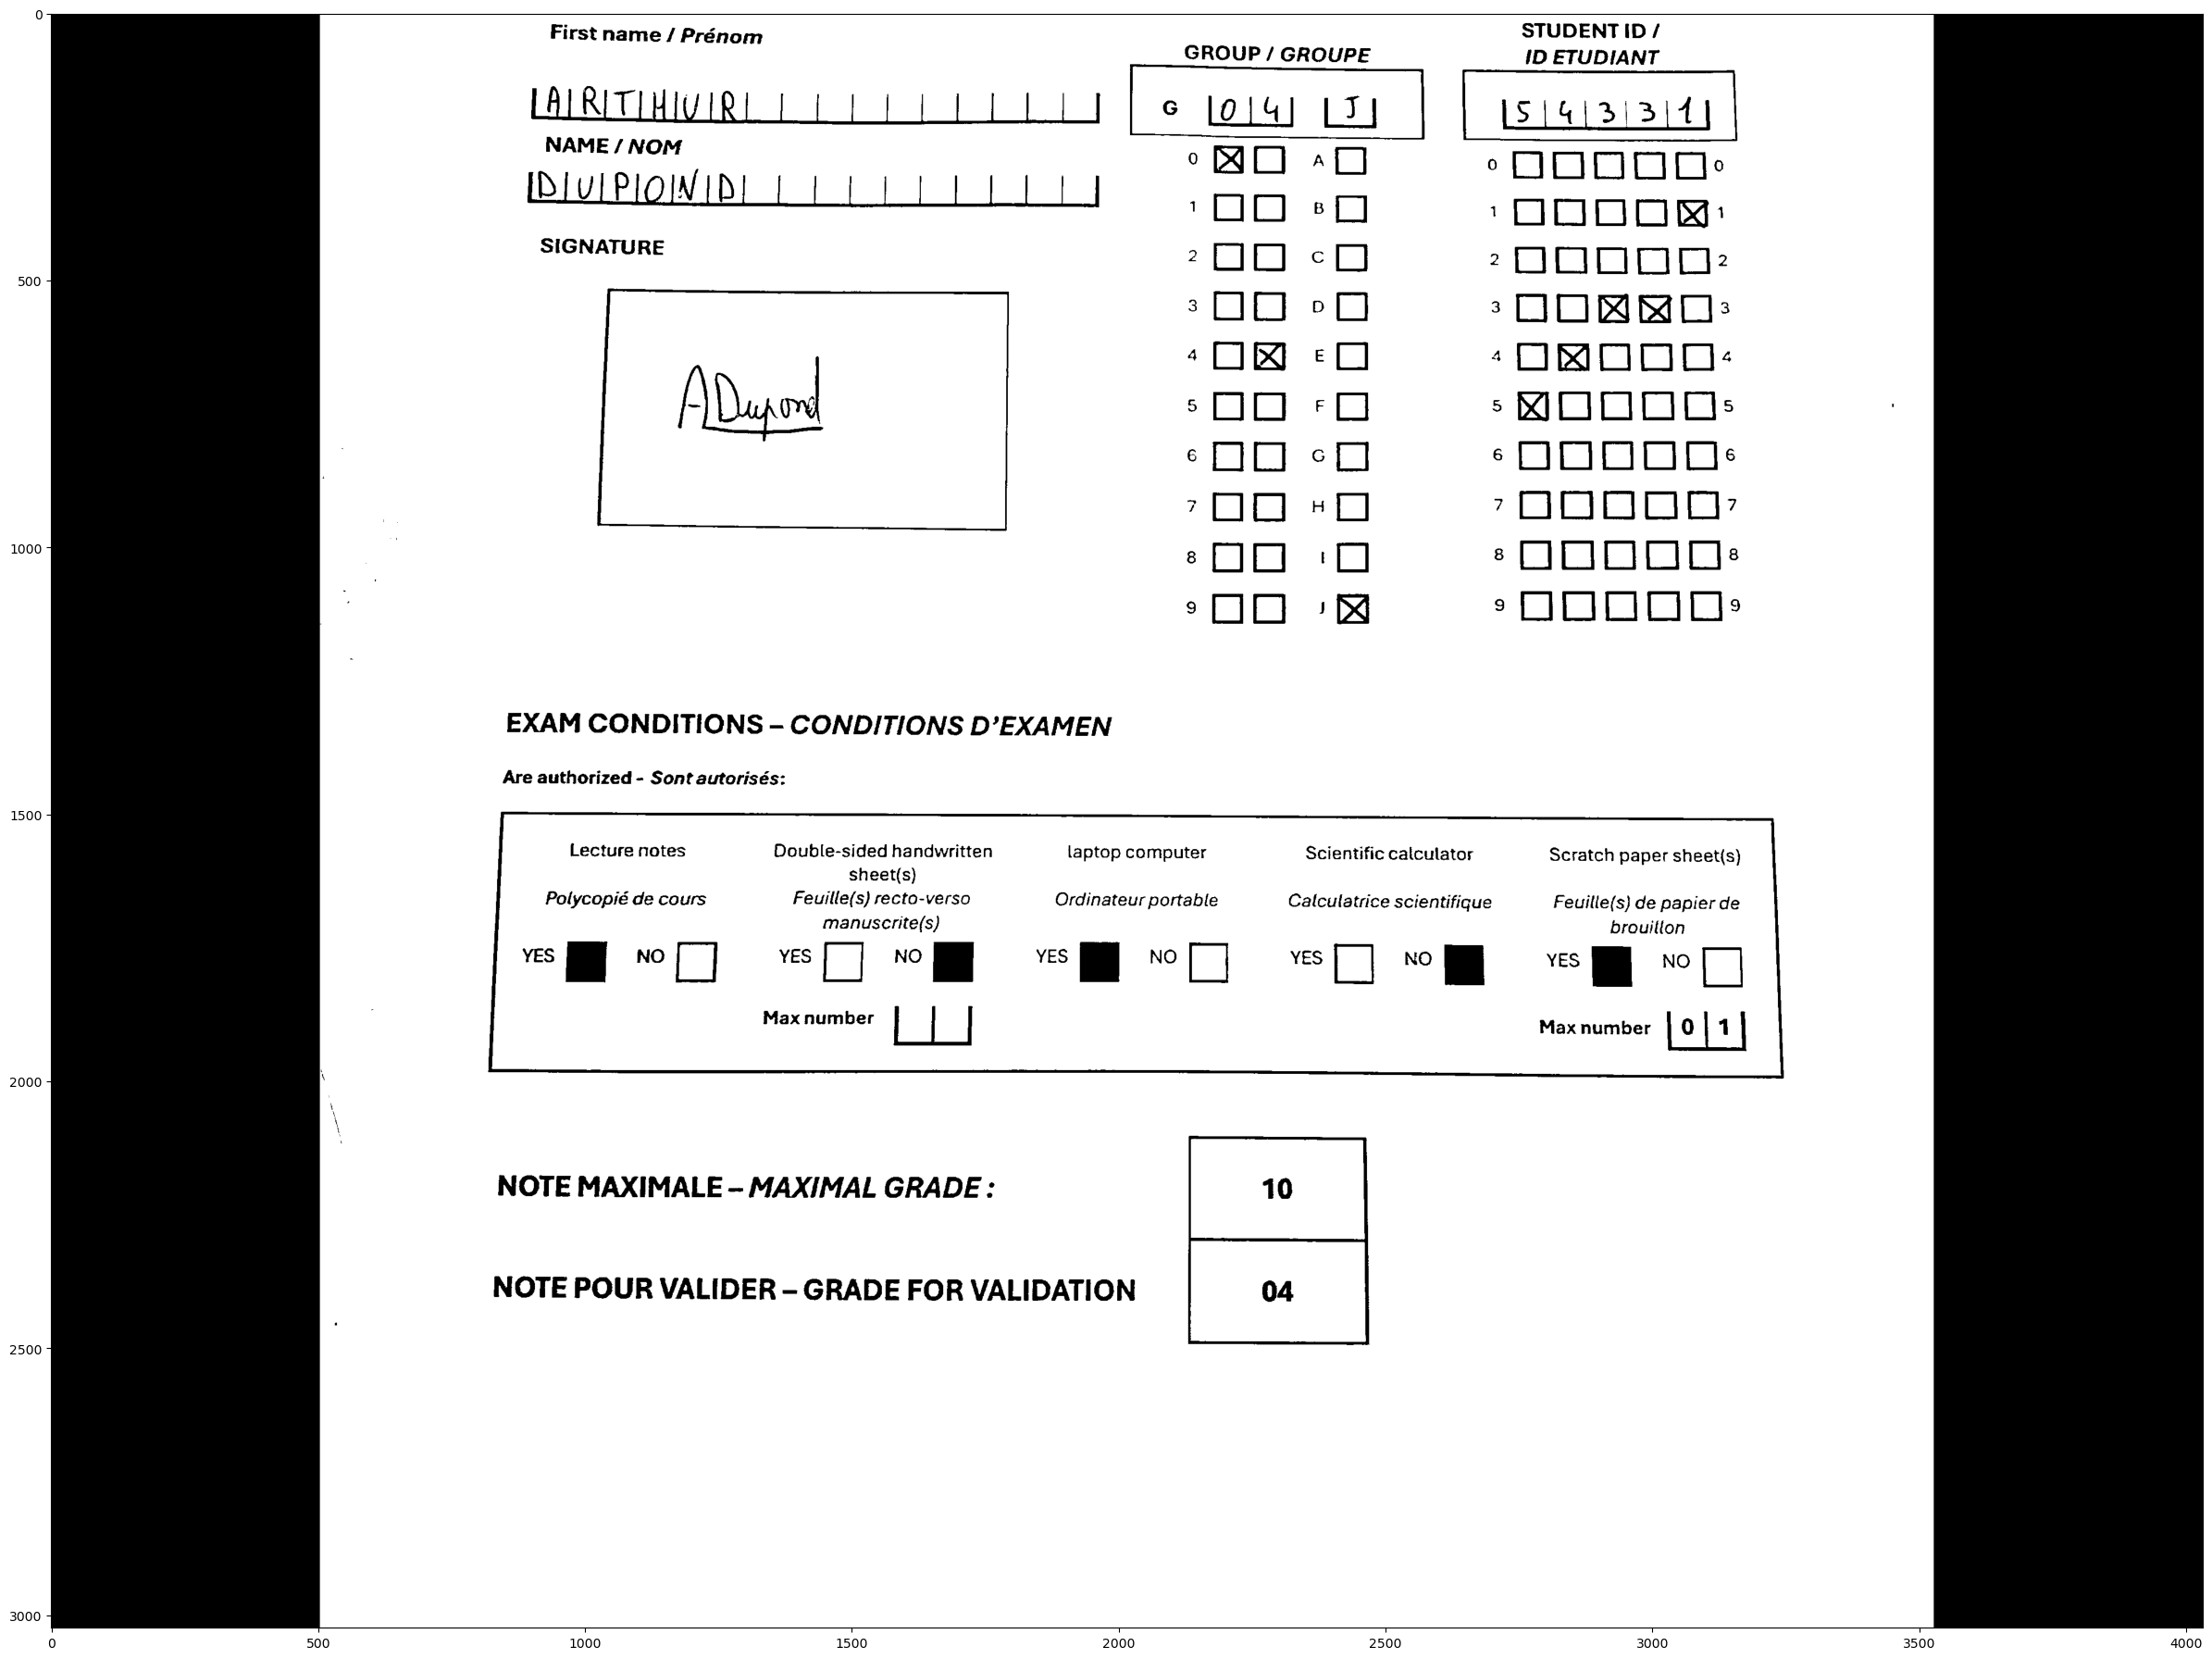

In [131]:
# 717 1510 779 1576
plt.figure(figsize=(30, 30))
plt.imshow(result, cmap='gray')

In [105]:
# --- 7. Récupération centres ---
coords = []

for k, size in filtered:
    min_row, min_col, max_row, max_col = regionprops[k].bbox
    cx = (min_col + max_col) / 2
    cy = (min_row + max_row) / 2
    



In [106]:
print(len(filtered))

80


In [107]:
print(im4.shape)

(4032, 3024)
